# Introduction to the tools

Milestone 3 of *Evaluating lineage link prediction with Valentine*.

This notebook shows, on a basic level, how the project-specific tools are used. General technologies (Python,
Jupyter, Git) are described in the README.

| tool | role in the project | section |
|---|---|---|
| [Valentine](https://delftdata.github.io/valentine/) 1.1 | the method we evaluate: scores how likely two columns correspond | 1 |
| [NetworkX](https://networkx.org/) | ground truth: lineage graph, bridging over temporary tables, relation of a pair | 2 |
| [scikit-learn](https://scikit-learn.org/) | evaluation: precision, recall, PR-AUC, AUROC (+ our Hits@k and MRR) | 3 |
| pandas, Matplotlib | tables and figures (used in every notebook) | - |

All examples use the pre-processed `train` split (`03_preprocessing.ipynb`, `src/preprocessing.py`).

In [1]:
import sys
import time
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..", "src").resolve()))

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from valentine import valentine_match
from valentine.algorithms import Coma, Cupid, DistributionBased, JaccardDistanceMatcher, SimilarityFlooding

from eda import evaluation_links, pair_label, usable
from lineage_data import load_all
from preprocessing import preprocess_all

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)

BLUE, GREY, LIGHT_GREY, MUTED, GRID, SURFACE = "#2a78d6", "#898781", "#c3c2b7", "#52514e", "#e1e0d9", "#ffffff"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 8, "axes.titlesize": 8.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

clean, _ = preprocess_all(load_all())
train = clean["train"]
tables = usable(train)
print(len(tables), "usable tables in train")

21 usable tables in train


## 1. Valentine

### 1.1 Matching two tables

`valentine_match` takes a list of DataFrames and a matcher and returns a `MatcherResults` object: a mapping from
`ColumnPair(source_table, source_column, target_table, target_column)` to a similarity score, sorted from high to
low. We match `Orders` with the view derived from it, `vwOrderFulfillment`.

In [2]:
def as_table(result, source_name):
    """Valentine's matches as a DataFrame, oriented from source_name to the other table."""
    rows = []
    for pair, score in result.items():
        source, target = ((pair.source_column, pair.target_column) if pair.source_table == source_name
                          else (pair.target_column, pair.source_column))
        rows.append({"source column": source, "target column": target, "score": score})
    return pd.DataFrame(rows, columns=["source column", "target column", "score"])


orders, view = tables["orders"], tables["vworderfulfillment"]
print("Orders:            ", list(orders.columns))
print("vwOrderFulfillment:", list(view.columns))

matches = valentine_match([orders, view], Coma(use_instances=True),
                          df_names=["Orders", "vwOrderFulfillment"], instance_sample_size=None)
as_table(matches, "Orders").head(8).round(3)

Orders:             ['OrderID', 'CustomerID', 'EmployeeID', 'OrderDate', 'RequiredDate', 'ShippedDate', 'ShipVia', 'Freight', 'ShipName', 'ShipAddress', 'ShipCity', 'ShipRegion', 'ShipPostalCode', 'ShipCountry']
vwOrderFulfillment: ['OrderID', 'CustomerName', 'ShipperName', 'OrderDate', 'RequiredDate']


,source column,target column,score
0,OrderID,OrderID,1.000
1,OrderDate,OrderDate,1.000
2,RequiredDate,RequiredDate,1.000
3,ShipName,CustomerName,0.737


`instance_sample_size=None` makes Valentine use all rows. Its default (1,000 random rows per table) would compare
different samples of the source and the derived table and lose part of the value overlap.

### 1.2 One-to-one matches and Valentine's own metrics

A column usually corresponds to at most one column in the other table. `one_to_one_hungarian()` keeps the best
one-to-one assignment, and `get_metrics()` compares the matches with a column-level ground truth:

In [3]:
one_to_one = matches.one_to_one_hungarian(threshold=0.3)
for pair, score in one_to_one.items():
    print(f"{pair.source_column:>14} -> {pair.target_column:<14} {score:.3f}")

ground_truth = [("OrderID", "OrderID"), ("OrderDate", "OrderDate"), ("RequiredDate", "RequiredDate")]
matches.get_metrics(ground_truth)

       OrderID -> OrderID        1.000
     OrderDate -> OrderDate      1.000
  RequiredDate -> RequiredDate   1.000
      ShipName -> CustomerName   0.737


{'MeanReciprocalRank': 1.0,
 'Precision': 0.75,
 'F1Score': 0.8571428571428571,
 'Recall': 1.0,
 'PrecisionTop10Percent': 1.0,
 'RecallAtSizeofGroundTruth': 1.0}

These column-level metrics are **not** our evaluation target: we need to know whether a whole table was derived
from another one (section 1.4), but they are a quick check that a matcher behaves as expected.

### 1.3 The five matchers on a renamed column

In `vwOrderFulfillment`, `Customers.CompanyName` was renamed to `CustomerName`. Schema-based matchers only see the
names, instance-based matchers only the values, COMA can use both. For each matcher we look at the score and rank
of the true pair among all column pairs of the two tables.

In [4]:
MATCHERS = {
    "COMA (schema)": ("schema", lambda: Coma()),
    "COMA (schema + instances)": ("schema + instances", lambda: Coma(use_instances=True)),
    "Cupid": ("schema", lambda: Cupid()),
    "Similarity Flooding": ("schema", lambda: SimilarityFlooding()),
    "Jaccard distance": ("instances", lambda: JaccardDistanceMatcher()),
    "Distribution-based": ("instances", lambda: DistributionBased()),
}

customers = tables["customers"]
true_pair = ("CompanyName", "CustomerName")
rows = []
for name, (family, make) in MATCHERS.items():
    start = time.perf_counter()
    result = valentine_match([customers, view], make(), df_names=["Customers", "vwOrderFulfillment"],
                             instance_sample_size=None)
    seconds = time.perf_counter() - start
    found = as_table(result, "Customers")
    ranked = list(zip(found["source column"], found["target column"]))
    rows.append({
        "matcher": name,
        "uses": family,
        "score of true pair": round(found.score[ranked.index(true_pair)], 3) if true_pair in ranked else 0.0,
        "rank of true pair": ranked.index(true_pair) + 1 if true_pair in ranked else "-",
        "pairs returned": len(found),
        "best pair": " -> ".join(ranked[0]) if ranked else "-",
        "seconds": round(seconds, 2),
    })
pd.DataFrame(rows)

,matcher,uses,score of true pair,rank of true pair,pairs returned,best pair,seconds
0,COMA (schema),schema,0.000,-,3,CustomerID -> CustomerName,0.04
1,COMA (schema + instances),schema + instances,0.749,1,6,CompanyName -> CustomerName,0.21
2,Cupid,schema,0.740,2,4,CompanyName -> ShipperName,5.56
3,Similarity Flooding,schema,0.178,2,55,CustomerID -> OrderID,0.24
4,Jaccard distance,instances,0.978,1,1,CompanyName -> CustomerName,0.10
5,Distribution-based,instances,0.989,1,1,CompanyName -> CustomerName,3.55


This small example already shows the pattern found in the EDA. Among the schema-based matchers, COMA does not
return the renamed pair at all, and Cupid and Similarity Flooding rank another pair first (`CompanyName -> ShipperName`,
`CustomerID -> OrderID`), because the names alone do not reveal the rename. Every matcher that looks at the values
(COMA with instances, Jaccard, Distribution-based) puts `CompanyName -> CustomerName` first. The running times
(from 0.04 s to over 5 s for one pair) matter too, because the experiments score all 842 candidate table pairs.

In [5]:
def best_per_target_column(result, target_name, target):
    best = dict.fromkeys(target.columns, 0.0)
    for pair, score in result.items():
        column = pair.target_column if pair.target_table == target_name else pair.source_column
        if column in best:
            best[column] = max(best[column], score)
    return pd.Series(best)


def table_score(best):
    ordered = best.sort_values(ascending=False)
    return {"max": ordered.iloc[0], "top3": ordered.head(3).mean(), "coverage": (best >= 0.5).mean()}


examples = []
for source in ["orders", "customers", "shippers", "suppliers", "employees", "products"]:
    result = valentine_match([tables[source], view], Coma(use_instances=True),
                             df_names=[train.display[source], "vwOrderFulfillment"], instance_sample_size=None)
    best = best_per_target_column(result, "vwOrderFulfillment", view)
    label = pair_label(train, evaluation_links(train), source, "vworderfulfillment")
    examples.append({"source": train.display[source], "relation": label, **table_score(best)})
pd.DataFrame(examples).round(2)

,source,relation,max,top3,coverage
0,Orders,lineage,1.00,1.00,0.8
1,Customers,lineage,0.75,0.36,0.2
2,Shippers,lineage,0.75,0.25,0.2
3,Suppliers,unrelated,0.27,0.27,0.0
4,Employees,unrelated,0.36,0.32,0.0
5,Products,unrelated,0.27,0.26,0.0


All three true sources of the view get a higher `max` score (1.00, 0.75, 0.75) than the unrelated tables
(0.27-0.36). `top3` and `coverage` clearly favour `Orders`, which gave three columns to the view, but barely separate
`Customers` and `Shippers`, which gave only one column each to the join. Which aggregation works best over all pairs
is one of the questions of Milestone 4.

In [6]:
test = clean["test"]
graph = nx.DiGraph(test.links)
print("nodes:", graph.number_of_nodes(), "| edges:", graph.number_of_edges())
for source, target in sorted(graph.edges):
    print(f"  {test.display[source]:>24} -> {test.display[target]}")

nodes: 7 | edges: 6
                Categories -> vwProductFullCatalog
                  Products -> vwProductFullCatalog
                 Suppliers -> vwProductFullCatalog
     TableInventoryStaging -> ##TempProcurementBuffer
   ##TempProcurementBuffer -> FinalProcurementAudit
      vwProductFullCatalog -> TableInventoryStaging


In [7]:
target = "finalprocurementaudit"
print("direct sources of FinalProcurementAudit:", [test.display[n] for n in graph.predecessors(target)])
print("all ancestors:                          ", sorted(test.display[n] for n in nx.ancestors(graph, target)))
print("longest chain (links):                  ", nx.dag_longest_path_length(graph))
print("objects without data:                   ", [test.display[n] for n in graph if n not in usable(test)])
print("evaluable links after bridging:")
for (source, target), kind in sorted(evaluation_links(test).items()):
    print(f"  {test.display[source]:>24} -> {test.display[target]:<24} {kind}")

direct sources of FinalProcurementAudit: ['##TempProcurementBuffer']
all ancestors:                           ['##TempProcurementBuffer', 'Categories', 'Products', 'Suppliers', 'TableInventoryStaging', 'vwProductFullCatalog']
longest chain (links):                   4
objects without data:                    ['##TempProcurementBuffer']
evaluable links after bridging:
                Categories -> vwProductFullCatalog     direct
                  Products -> vwProductFullCatalog     direct
                 Suppliers -> vwProductFullCatalog     direct
     TableInventoryStaging -> FinalProcurementAudit    bridged
      vwProductFullCatalog -> TableInventoryStaging    direct


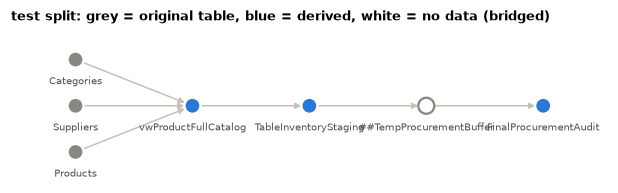

In [8]:
for layer, nodes in enumerate(nx.topological_generations(graph)):
    for node in nodes:
        graph.nodes[node]["layer"] = layer
pos = nx.multipartite_layout(graph, subset_key="layer", align="vertical")
data = usable(test)
fig, ax = plt.subplots(figsize=(7.0, 1.8))
nx.draw_networkx_edges(graph, pos, ax=ax, edge_color=LIGHT_GREY, arrowsize=8, node_size=110)
nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=110, linewidths=1.5,
                       node_color=[SURFACE if n not in data else GREY if test.kind(n) == "original" else BLUE for n in graph],
                       edgecolors=[GREY if n not in data else SURFACE for n in graph])
for node, (x, y) in pos.items():
    ax.text(x, y - 0.14, test.display[node], ha="center", va="top", fontsize=6.5, color=MUTED)
ax.set_title("test split: grey = original table, blue = derived, white = no data (bridged)")
ax.axis("off")
ax.margins(x=0.08, y=0.25)
plt.show()

## 3. scikit-learn: evaluating a ranking

The final output of the method is a score for each candidate pair, which we evaluate as a ranking. As a small
example we rank all 20 candidate sources of `vwOrderFulfillment` with the `top3` table score of the fast
schema-only COMA, and evaluate the ranking with scikit-learn (threshold-free PR-AUC and AUROC, plus precision and
recall at a threshold) and two ranking metrics of the baseline paper that we implement ourselves.

In [9]:
links = evaluation_links(train)
ranking = []
for source in tables:
    if source == "vworderfulfillment":
        continue
    result = valentine_match([tables[source], view], Coma(), df_names=[train.display[source], "vwOrderFulfillment"])
    best = best_per_target_column(result, "vwOrderFulfillment", view)
    ranking.append({"source": train.display[source], "score": table_score(best)["top3"],
                    "is_lineage": (source, "vworderfulfillment") in links})
ranking = pd.DataFrame(ranking).sort_values("score", ascending=False, ignore_index=True)
ranking.index += 1
ranking.head(6).round(3)

,source,score,is_lineage
1,TableFulfillmentLeads,1.000,False
2,Orders,1.000,True
3,vwOrderEmployeeContext,0.833,False
4,TableRegionalAssignments,0.600,False
5,vwEmployeeHierarchy,0.500,False
6,Products,0.500,False


In [10]:
def hits_at_k(ranked_labels, k):
    """1 if a true source is among the first k candidates."""
    return float(any(ranked_labels[:k]))


def reciprocal_rank(ranked_labels):
    """1 / rank of the first true source (averaged over targets this gives MRR)."""
    return next((1 / rank for rank, label in enumerate(ranked_labels, start=1) if label), 0.0)


y_true, y_score = ranking.is_lineage, ranking.score
y_pred = y_score >= 0.5
pd.Series({
    "precision (score >= 0.5)": precision_score(y_true, y_pred, zero_division=0),
    "recall (score >= 0.5)": recall_score(y_true, y_pred),
    "PR-AUC (average precision)": average_precision_score(y_true, y_score),
    "AUROC": roc_auc_score(y_true, y_score),
    "Hits@1": hits_at_k(list(y_true), 1),
    "Hits@3": hits_at_k(list(y_true), 3),
    "reciprocal rank": reciprocal_rank(list(y_true)),
}).round(3).to_frame("value")

,value
precision (score >= 0.5),0.091
recall (score >= 0.5),0.333
PR-AUC (average precision),0.299
AUROC,0.598
Hits@1,0.000
Hits@3,1.000
reciprocal rank,0.500


The ranking also shows a problem the EDA predicted: the top candidate, `TableFulfillmentLeads`, is not a source of
the view but a table **derived from it** (a `reverse` pair). Column matching is symmetric, so the direction of a
link has to be decided separately, which is one of our planned experiments.

In the experiments the same functions are applied to all 842 candidate pairs (PR-AUC, AUROC) and to the candidate
sources of every derived table (Hits@k, MRR), for every matcher and aggregation.